# 9.3 — Webpage photographs and every scoring measurement

Standalone demo: discover images → fetch into a **temporary directory** → use existing `pipeline.score_photo()` → show preview, criterion scores, explanations, and **all CV measurements**.

No API, database, worker, or extra scoring logic. With `SAVE_IMAGES = False`, downloaded files are deleted after scoring, but small image previews remain in memory for this notebook. HTTP image fetching is still necessary.

This example defaults to the CV-only five-criterion configuration; criteria requiring a subject detector may be reported as unavailable. All recorded measurements and reasons are still shown. The thresholds are demonstrations, not validated brand standards.


In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'src' / 'brandlens').is_dir())
from brandlens.config import load_cv_config
from brandlens.crawler.discovery import DiscoverySettings
from brandlens.crawler_pipeline import run_crawler_pipeline


## Run the crawler and scoring pipeline

Set `SAVE_IMAGES=True` only if you want to retain the files under `OUTPUT_DIR`. The notebook displays previews regardless. Use the same working `discovery.py` with your existing User-Agent; do not replace that module.


In [4]:
URL = 'https://www.w3schools.com/html/html_images.asp'
SAVE_IMAGES = False  # Change to True to keep the original downloaded files
OUTPUT_DIR = ROOT / 'data' / 'crawled_images' / 'test_9_3'
CONFIG_PATH = ROOT / 'config' / "test_config" / 'brand_standards_cv_only_test.json'
# For a smaller demo instead: brand_standards_brightness_contrast_test.json
SCHEMA_PATH = ROOT / "config" / "brand_standards.schema.json"

discovery_settings = DiscoverySettings(
    max_pages=3,
    max_images=30,
    page_follow_mode="pagination",
)

configuration = load_cv_config(CONFIG_PATH, schema_path=SCHEMA_PATH)
result = await run_crawler_pipeline(
    URL,
    configuration,
    save_images=SAVE_IMAGES,
    output_dir=OUTPUT_DIR if SAVE_IMAGES else None,
    discovery_settings=discovery_settings,
)

print('Webpages visited:', len(result.discovery.pages_visited))
print('Image URLs discovered:', len(result.discovery.image_urls))
print("Unique images analyzed:", len(result.images))
print("Duplicate images skipped:", result.duplicate_count)
print('Images with scores:', sum(p['score'] is not None for p in result.images))
print('Page failures:', len(result.discovery.failed_pages))
print('Download failures:', len(result.download_failures))
print('Originals saved:', SAVE_IMAGES)


image download skipped https://www.w3schools.com/adventure/img/lynx-7.webp (unsupported_type): Animated or multi-frame images are not supported.


Webpages visited: 1
Image URLs discovered: 20
Unique images analyzed: 19
Duplicate images skipped: 0
Images with scores: 13
Page failures: 0
Download failures: 1
Originals saved: False


## Preview every image with scores, explanations, and all measurements

One table summarizes every criterion (including unavailable criteria and their reasons). The next table shows **every measurement name and value** returned by the CV analyzers; no measurement filtering is applied. Raw VLM results are displayed too when the pipeline has a VLM client.



=== Image 1: https://www.w3schools.com/images/og/html/html_images.png ===


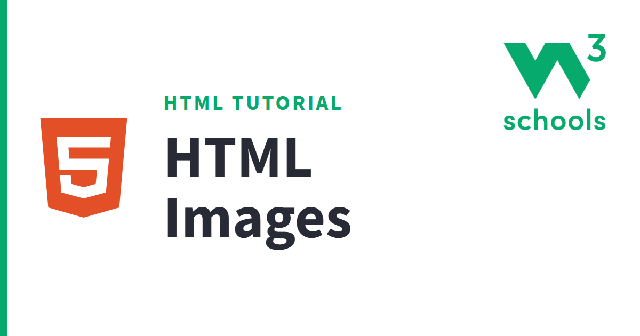

Overall score: 36.64407532134189 | status: partial | flagged: True


,Criterion,Score,Availability,Applied weight,Rule,Explanation / evidence,Reasons / needs review
0,exposure_brightness,0.000000,ok,0.3,pass_fail_thresholds,mean_luminance 240.866 >= mean_luminance_min 40 | mean_luminance 240.866 <= mean_luminance_max 215 | near_black_fraction 0 <= near_black_fraction_max 0.2 | near_white_fraction 0.90875 <= near_white_fraction_max 0.2,mean_luminance 240.866 <= mean_luminance_max 215 | near_white_fraction 0.90875 <= near_white_fraction_max 0.2
1,contrast,0.000000,ok,0.3,pass_fail_thresholds,luminance_std 46.4758 >= luminance_std_min 20 | luminance_std 46.4758 <= luminance_std_max 90 | p5_p95_range 141 >= p5_p95_range_min 50 | p5_p95_range 141 <= p5_p95_range_max 240 | near_black_fraction 0 <= near_black_fraction_max 0.2 | near_white_fraction 0.90875 <= near_white_fraction_max 0.2,near_white_fraction 0.90875 <= near_white_fraction_max 0.2
2,color_palette_fit,91.610188,ok,0.4,linear_distance_to_0_100,palette_distance 3.35592 mapped by linear_distance_to_0_100 with palette_distance_max 40 -> 91.6102,
3,framing_subject_position,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.
4,sharpness_subject_emphasis,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.


All CV measurements:


,Criterion,Measurement,Value
0,exposure_brightness,mean_luminance,240.86641534391535
1,exposure_brightness,near_black_fraction,0.0
2,exposure_brightness,near_white_fraction,0.90875
3,contrast,luminance_std,46.47583683063612
4,contrast,p5_p95_range,141.0
5,contrast,near_black_fraction,0.0
6,contrast,near_white_fraction,0.90875
7,color_palette_fit,dominant_colors,"[{'rgb': [255, 255, 255], 'hex': '#FFFFFF', 'lab': [99.98209111317912, -0.010058576578197198, 0.011957438565785905], 'proportion': 0.9106931216931217}, {'rgb': [14, 170, 110], 'hex': '#0EAA6E', 'lab': [61.771229404309544, -51.02143734157152, 21.036567252851867], 'proportion': 0.03187698412698413}, {'rgb': [42, 44, 54], 'hex': '#2A2C36', 'lab': [18.03024323803406, 2.0713386031966694, -7.243115879082733], 'proportion': 0.02820238095238095}, {'rgb': [227, 80, 39], 'hex': '#E35027', 'lab': [54.19267648325207, 55.300943490415236, 52.5210787739615], 'proportion': 0.024931216931216933}, {'rgb': [178, 183, 175], 'hex': '#B2B7AF', 'lab': [73.76012923869678, -3.166821808510637, 3.603656914893617], 'proportion': 0.004296296296296296}]"
8,color_palette_fit,palette_distance,3.355924678658114



=== Image 2: https://www.w3schools.com/adventure/img/mascot-lynx.png ===


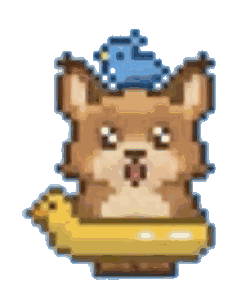

Overall score: 16.099676338027148 | status: partial | flagged: True


,Criterion,Score,Availability,Applied weight,Rule,Explanation / evidence,Reasons / needs review
0,exposure_brightness,0.000000,ok,0.3,pass_fail_thresholds,mean_luminance 195.896 >= mean_luminance_min 40 | mean_luminance 195.896 <= mean_luminance_max 215 | near_black_fraction 0 <= near_black_fraction_max 0.2 | near_white_fraction 0.489889 <= near_white_fraction_max 0.2,near_white_fraction 0.489889 <= near_white_fraction_max 0.2
1,contrast,0.000000,ok,0.3,pass_fail_thresholds,luminance_std 66.5015 >= luminance_std_min 20 | luminance_std 66.5015 <= luminance_std_max 90 | p5_p95_range 175 >= p5_p95_range_min 50 | p5_p95_range 175 <= p5_p95_range_max 240 | near_black_fraction 0 <= near_black_fraction_max 0.2 | near_white_fraction 0.489889 <= near_white_fraction_max 0.2,near_white_fraction 0.489889 <= near_white_fraction_max 0.2
2,color_palette_fit,40.249191,ok,0.4,linear_distance_to_0_100,palette_distance 23.9003 mapped by linear_distance_to_0_100 with palette_distance_max 40 -> 40.2492,
3,framing_subject_position,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.
4,sharpness_subject_emphasis,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.


All CV measurements:


,Criterion,Measurement,Value
0,exposure_brightness,mean_luminance,195.89584377302873
1,exposure_brightness,near_black_fraction,0.0
2,exposure_brightness,near_white_fraction,0.4898894620486367
3,contrast,luminance_std,66.50147342719096
4,contrast,p5_p95_range,175.0
5,contrast,near_black_fraction,0.0
6,contrast,near_white_fraction,0.4898894620486367
7,color_palette_fit,dominant_colors,"[{'rgb': [255, 255, 255], 'hex': '#FFFFFF', 'lab': [99.94356518847165, -0.015693242477545333, 0.09523616952378688], 'proportion': 0.49385408990420043}, {'rgb': [209, 157, 108], 'hex': '#D19D6C', 'lab': [68.47350909737577, 13.454645716729207, 33.17042878057688], 'proportion': 0.19314664701547532}, {'rgb': [120, 79, 44], 'hex': '#784F2C', 'lab': [37.2829678065673, 13.36333655973441, 27.119061117257083], 'proportion': 0.13521002210759028}, {'rgb': [102, 132, 159], 'hex': '#66849F', 'lab': [53.94071458039859, -3.714942226890855, -17.832977224980333], 'proportion': 0.10561532792925571}, {'rgb': [221, 175, 52], 'hex': '#DDAF34', 'lab': [73.80631778827001, 5.209105633314859, 65.29600886918018], 'proportion': 0.07217391304347825}]"
8,color_palette_fit,palette_distance,23.900323661972852



=== Image 3: https://www.w3schools.com/adventure/img/screen-map.png ===


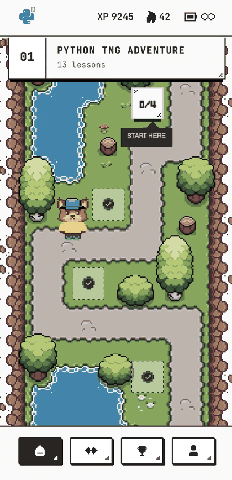

Overall score: 10.667560832760655 | status: partial | flagged: True


,Criterion,Score,Availability,Applied weight,Rule,Explanation / evidence,Reasons / needs review
0,exposure_brightness,0.000000,ok,0.3,pass_fail_thresholds,mean_luminance 165.172 >= mean_luminance_min 40 | mean_luminance 165.172 <= mean_luminance_max 215 | near_black_fraction 0.00628977 <= near_black_fraction_max 0.2 | near_white_fraction 0.284274 <= near_white_fraction_max 0.2,near_white_fraction 0.284274 <= near_white_fraction_max 0.2
1,contrast,0.000000,ok,0.3,pass_fail_thresholds,luminance_std 69.2313 >= luminance_std_min 20 | luminance_std 69.2313 <= luminance_std_max 90 | p5_p95_range 209 >= p5_p95_range_min 50 | p5_p95_range 209 <= p5_p95_range_max 240 | near_black_fraction 0.00628977 <= near_black_fraction_max 0.2 | near_white_fraction 0.284274 <= near_white_fraction_max 0.2,near_white_fraction 0.284274 <= near_white_fraction_max 0.2
2,color_palette_fit,26.668902,ok,0.4,linear_distance_to_0_100,palette_distance 29.3324 mapped by linear_distance_to_0_100 with palette_distance_max 40 -> 26.6689,
3,framing_subject_position,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.
4,sharpness_subject_emphasis,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.


All CV measurements:


,Criterion,Measurement,Value
0,exposure_brightness,mean_luminance,165.172492868115
1,exposure_brightness,near_black_fraction,0.006289773974105771
2,exposure_brightness,near_white_fraction,0.2842741935483871
3,contrast,luminance_std,69.23128174741497
4,contrast,p5_p95_range,209.0
5,contrast,near_black_fraction,0.006289773974105771
6,contrast,near_white_fraction,0.2842741935483871
7,color_palette_fit,dominant_colors,"[{'rgb': [250, 250, 249], 'hex': '#FAFAF9', 'lab': [98.13339016742341, -0.0908088235294171, 0.11224433739012163], 'proportion': 0.29484858459512836}, {'rgb': [136, 169, 93], 'hex': '#88A95D', 'lab': [65.20899112505741, -24.303345946453284, 35.4974808461026], 'proportion': 0.241430765854729}, {'rgb': [186, 168, 158], 'hex': '#BAA89E', 'lab': [70.12971234472293, 4.647833930760877, 7.568010977737941], 'proportion': 0.21279350449857362}, {'rgb': [66, 57, 49], 'hex': '#423931', 'lab': [24.642762202759464, 2.817399245568872, 6.2437282645277], 'proportion': 0.17635231511959623}, {'rgb': [36, 135, 174], 'hex': '#2487AE', 'lab': [52.805918731565114, -14.5493032953619, -28.0189432465419], 'proportion': 0.07457482993197279}]"
8,color_palette_fit,palette_distance,29.332439167239347



=== Image 4: https://www.w3schools.com/images/colorpicker2000.png ===


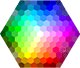

Overall score: 3.3893630716147394 | status: partial | flagged: True


,Criterion,Score,Availability,Applied weight,Rule,Explanation / evidence,Reasons / needs review
0,exposure_brightness,0.000000,ok,0.3,pass_fail_thresholds,mean_luminance 164.422 >= mean_luminance_min 40 | mean_luminance 164.422 <= mean_luminance_max 215 | near_black_fraction 0 <= near_black_fraction_max 0.2 | near_white_fraction 0.250919 <= near_white_fraction_max 0.2,near_white_fraction 0.250919 <= near_white_fraction_max 0.2
1,contrast,0.000000,ok,0.3,pass_fail_thresholds,luminance_std 71.6633 >= luminance_std_min 20 | luminance_std 71.6633 <= luminance_std_max 90 | p5_p95_range 200 >= p5_p95_range_min 50 | p5_p95_range 200 <= p5_p95_range_max 240 | near_black_fraction 0 <= near_black_fraction_max 0.2 | near_white_fraction 0.250919 <= near_white_fraction_max 0.2,near_white_fraction 0.250919 <= near_white_fraction_max 0.2
2,color_palette_fit,8.473408,ok,0.4,linear_distance_to_0_100,palette_distance 36.6106 mapped by linear_distance_to_0_100 with palette_distance_max 40 -> 8.47341,
3,framing_subject_position,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.
4,sharpness_subject_emphasis,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.


All CV measurements:


,Criterion,Measurement,Value
0,exposure_brightness,mean_luminance,164.42242647058825
1,exposure_brightness,near_black_fraction,0.0
2,exposure_brightness,near_white_fraction,0.2509191176470588
3,contrast,luminance_std,71.66326647424955
4,contrast,p5_p95_range,200.0
5,contrast,near_black_fraction,0.0
6,contrast,near_white_fraction,0.2509191176470588
7,color_palette_fit,dominant_colors,"[{'rgb': [240, 247, 243], 'hex': '#F0F7F3', 'lab': [96.73286937429475, -3.061556503950305, 1.0189140095936806], 'proportion': 0.32573529411764707}, {'rgb': [134, 208, 83], 'hex': '#86D053', 'lab': [76.51738196447955, -44.18525765539357, 53.66063471206625], 'proportion': 0.2011029411764706}, {'rgb': [155, 61, 215], 'hex': '#9B3DD7', 'lab': [46.00505920118138, 63.52348983253545, -62.44706937798973], 'proportion': 0.1922794117647059}, {'rgb': [211, 86, 68], 'hex': '#D35644', 'lab': [52.92394745215953, 48.37652738764001, 35.61009480337122], 'proportion': 0.1636029411764706}, {'rgb': [90, 147, 207], 'hex': '#5A93CF', 'lab': [59.568106064774184, -1.4816363458528556, -36.30399061032868], 'proportion': 0.11727941176470588}]"
8,color_palette_fit,palette_distance,36.61063692838526



=== Image 5: https://www.w3schools.com/html/images/yt_logo_rgb_dark.webp ===


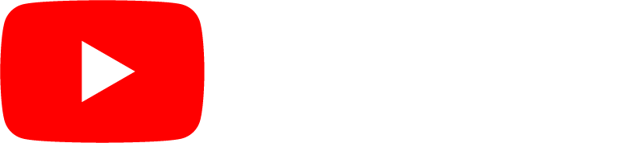

Overall score: 31.28026603385953 | status: partial | flagged: True


,Criterion,Score,Availability,Applied weight,Rule,Explanation / evidence,Reasons / needs review
0,exposure_brightness,0.000000,ok,0.3,pass_fail_thresholds,mean_luminance 204.599 >= mean_luminance_min 40 | mean_luminance 204.599 <= mean_luminance_max 215 | near_black_fraction 0 <= near_black_fraction_max 0.2 | near_white_fraction 0.715231 <= near_white_fraction_max 0.2,near_white_fraction 0.715231 <= near_white_fraction_max 0.2
1,contrast,0.000000,ok,0.3,pass_fail_thresholds,luminance_std 80.2609 >= luminance_std_min 20 | luminance_std 80.2609 <= luminance_std_max 90 | p5_p95_range 179 >= p5_p95_range_min 50 | p5_p95_range 179 <= p5_p95_range_max 240 | near_black_fraction 0 <= near_black_fraction_max 0.2 | near_white_fraction 0.715231 <= near_white_fraction_max 0.2,near_white_fraction 0.715231 <= near_white_fraction_max 0.2
2,color_palette_fit,78.200665,ok,0.4,linear_distance_to_0_100,palette_distance 8.71973 mapped by linear_distance_to_0_100 with palette_distance_max 40 -> 78.2007,
3,framing_subject_position,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.
4,sharpness_subject_emphasis,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.


All CV measurements:


,Criterion,Measurement,Value
0,exposure_brightness,mean_luminance,204.59856932612573
1,exposure_brightness,near_black_fraction,0.0
2,exposure_brightness,near_white_fraction,0.7152308040641893
3,contrast,luminance_std,80.26087331150057
4,contrast,p5_p95_range,179.0
5,contrast,near_black_fraction,0.0
6,contrast,near_white_fraction,0.7152308040641893
7,color_palette_fit,dominant_colors,"[{'rgb': [255, 255, 255], 'hex': '#FFFFFF', 'lab': [99.99768596138523, 0.002879013327468982, 0.0010408807661832498], 'proportion': 0.7156128831404069}, {'rgb': [255, 0, 0], 'hex': '#FF0000', 'lab': [53.242507880971885, 80.0900960642326, 67.19073611907604], 'proportion': 0.27882574363909096}, {'rgb': [255, 131, 130], 'hex': '#FF8382', 'lab': [68.7784265588831, 47.21079282407408, 22.166232638888886], 'proportion': 0.0023278521495485806}, {'rgb': [255, 68, 67], 'hex': '#FF4443', 'lab': [57.91924055232556, 69.3933502906977, 43.661155523255815], 'proportion': 0.0017335069198766025}, {'rgb': [255, 199, 199], 'hex': '#FFC7C7', 'lab': [85.13802664620536, 20.00267857142857, 7.783705357142859], 'proportion': 0.001500014151076897}]"
8,color_palette_fit,palette_distance,8.719733966140469



=== Image 6: https://www.w3schools.com/html/images/yt_logo_rgb_dark.png ===


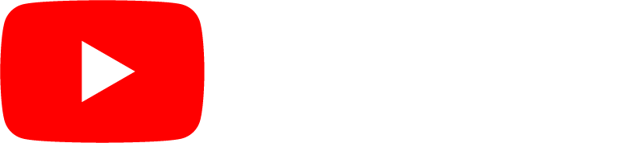

Overall score: 31.28026603385953 | status: partial | flagged: True


,Criterion,Score,Availability,Applied weight,Rule,Explanation / evidence,Reasons / needs review
0,exposure_brightness,0.000000,ok,0.3,pass_fail_thresholds,mean_luminance 204.599 >= mean_luminance_min 40 | mean_luminance 204.599 <= mean_luminance_max 215 | near_black_fraction 0 <= near_black_fraction_max 0.2 | near_white_fraction 0.715231 <= near_white_fraction_max 0.2,near_white_fraction 0.715231 <= near_white_fraction_max 0.2
1,contrast,0.000000,ok,0.3,pass_fail_thresholds,luminance_std 80.2609 >= luminance_std_min 20 | luminance_std 80.2609 <= luminance_std_max 90 | p5_p95_range 179 >= p5_p95_range_min 50 | p5_p95_range 179 <= p5_p95_range_max 240 | near_black_fraction 0 <= near_black_fraction_max 0.2 | near_white_fraction 0.715231 <= near_white_fraction_max 0.2,near_white_fraction 0.715231 <= near_white_fraction_max 0.2
2,color_palette_fit,78.200665,ok,0.4,linear_distance_to_0_100,palette_distance 8.71973 mapped by linear_distance_to_0_100 with palette_distance_max 40 -> 78.2007,
3,framing_subject_position,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.
4,sharpness_subject_emphasis,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.


All CV measurements:


,Criterion,Measurement,Value
0,exposure_brightness,mean_luminance,204.59856932612573
1,exposure_brightness,near_black_fraction,0.0
2,exposure_brightness,near_white_fraction,0.7152308040641893
3,contrast,luminance_std,80.26087331150057
4,contrast,p5_p95_range,179.0
5,contrast,near_black_fraction,0.0
6,contrast,near_white_fraction,0.7152308040641893
7,color_palette_fit,dominant_colors,"[{'rgb': [255, 255, 255], 'hex': '#FFFFFF', 'lab': [99.99768596138523, 0.002879013327468982, 0.0010408807661832498], 'proportion': 0.7156128831404069}, {'rgb': [255, 0, 0], 'hex': '#FF0000', 'lab': [53.24250788097188, 80.0900960642326, 67.19073611907604], 'proportion': 0.27882574363909096}, {'rgb': [255, 131, 130], 'hex': '#FF8382', 'lab': [68.7784265588831, 47.21079282407408, 22.166232638888886], 'proportion': 0.0023278521495485806}, {'rgb': [255, 68, 67], 'hex': '#FF4443', 'lab': [57.91924055232556, 69.3933502906977, 43.661155523255815], 'proportion': 0.0017335069198766025}, {'rgb': [255, 199, 199], 'hex': '#FFC7C7', 'lab': [85.13802664620536, 20.00267857142857, 7.783705357142859], 'proportion': 0.001500014151076897}]"
8,color_palette_fit,palette_distance,8.719733966140469



=== Image 7: https://www.w3schools.com/html/images/13_html_images.webp ===


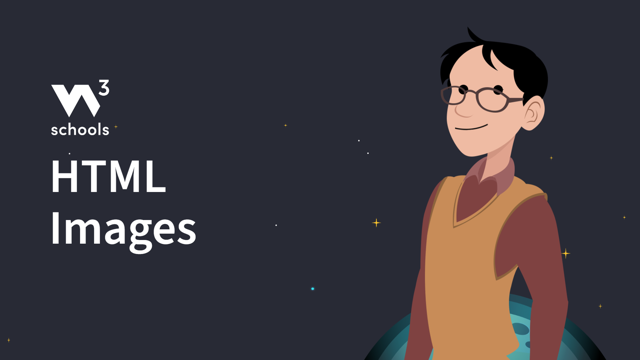

Overall score: 70.62372385461873 | status: partial | flagged: False


,Criterion,Score,Availability,Applied weight,Rule,Explanation / evidence,Reasons / needs review
0,exposure_brightness,100.00000,ok,0.3,pass_fail_thresholds,mean_luminance 60.2325 >= mean_luminance_min 40 | mean_luminance 60.2325 <= mean_luminance_max 215 | near_black_fraction 0.0124793 <= near_black_fraction_max 0.2 | near_white_fraction 0.0180821 <= near_white_fraction_max 0.2,
1,contrast,100.00000,ok,0.3,pass_fail_thresholds,luminance_std 46.054 >= luminance_std_min 20 | luminance_std 46.054 <= luminance_std_max 90 | p5_p95_range 110 >= p5_p95_range_min 50 | p5_p95_range 110 <= p5_p95_range_max 240 | near_black_fraction 0.0124793 <= near_black_fraction_max 0.2 | near_white_fraction 0.0180821 <= near_white_fraction_max 0.2,
2,color_palette_fit,26.55931,ok,0.4,linear_distance_to_0_100,palette_distance 29.3763 mapped by linear_distance_to_0_100 with palette_distance_max 40 -> 26.5593,
3,framing_subject_position,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.
4,sharpness_subject_emphasis,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.


All CV measurements:


,Criterion,Measurement,Value
0,exposure_brightness,mean_luminance,60.232538097993825
1,exposure_brightness,near_black_fraction,0.01247926311728395
2,exposure_brightness,near_white_fraction,0.01808207947530864
3,contrast,luminance_std,46.05396041680165
4,contrast,p5_p95_range,110.0
5,contrast,near_black_fraction,0.01247926311728395
6,contrast,near_white_fraction,0.01808207947530864
7,color_palette_fit,dominant_colors,"[{'rgb': [40, 42, 52], 'hex': '#282A34', 'lab': [17.168066225577668, 1.8931972129390573, -7.207686052756202], 'proportion': 0.8398625578703703}, {'rgb': [198, 139, 87], 'hex': '#C68B57', 'lab': [62.51886826031496, 16.879283239219543, 36.501042736140256], 'proportion': 0.05910686728395062}, {'rgb': [129, 69, 67], 'hex': '#814543', 'lab': [36.53571686551766, 25.36927232325278, 12.251487791172742], 'proportion': 0.04839023919753086}, {'rgb': [233, 182, 159], 'hex': '#E9B69F', 'lab': [78.06512925418498, 15.43621683512307, 18.779443698673283], 'proportion': 0.030706500771604937}, {'rgb': [237, 244, 244], 'hex': '#EDF4F4', 'lab': [95.63627621876338, -2.1976602979274533, -0.9322242012089803], 'proportion': 0.02193383487654321}]"
8,color_palette_fit,palette_distance,29.376276145381276



=== Image 8: https://www.w3schools.com/html/images/13_html_images.png ===


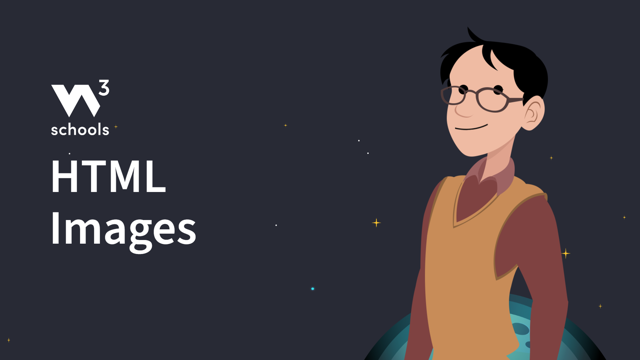

Overall score: 70.61916578676679 | status: partial | flagged: False


,Criterion,Score,Availability,Applied weight,Rule,Explanation / evidence,Reasons / needs review
0,exposure_brightness,100.000000,ok,0.3,pass_fail_thresholds,mean_luminance 60.235 >= mean_luminance_min 40 | mean_luminance 60.235 <= mean_luminance_max 215 | near_black_fraction 0.0124851 <= near_black_fraction_max 0.2 | near_white_fraction 0.018083 <= near_white_fraction_max 0.2,
1,contrast,100.000000,ok,0.3,pass_fail_thresholds,luminance_std 46.0603 >= luminance_std_min 20 | luminance_std 46.0603 <= luminance_std_max 90 | p5_p95_range 110 >= p5_p95_range_min 50 | p5_p95_range 110 <= p5_p95_range_max 240 | near_black_fraction 0.0124851 <= near_black_fraction_max 0.2 | near_white_fraction 0.018083 <= near_white_fraction_max 0.2,
2,color_palette_fit,26.547914,ok,0.4,linear_distance_to_0_100,palette_distance 29.3808 mapped by linear_distance_to_0_100 with palette_distance_max 40 -> 26.5479,
3,framing_subject_position,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.
4,sharpness_subject_emphasis,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.


All CV measurements:


,Criterion,Measurement,Value
0,exposure_brightness,mean_luminance,60.23495707947531
1,exposure_brightness,near_black_fraction,0.012485050154320988
2,exposure_brightness,near_white_fraction,0.018083043981481483
3,contrast,luminance_std,46.06033494431384
4,contrast,p5_p95_range,110.0
5,contrast,near_black_fraction,0.012485050154320988
6,contrast,near_white_fraction,0.018083043981481483
7,color_palette_fit,dominant_colors,"[{'rgb': [40, 42, 52], 'hex': '#282A34', 'lab': [17.164955535340315, 1.8941998925628143, -7.209385818312591], 'proportion': 0.8397526041666666}, {'rgb': [198, 139, 87], 'hex': '#C68B57', 'lab': [62.51170379920534, 16.873968311666076, 36.50445283099601], 'proportion': 0.059111689814814815}, {'rgb': [129, 69, 68], 'hex': '#814544', 'lab': [36.55438588522528, 25.328360873113205, 12.226865310077454], 'proportion': 0.048489583333333336}, {'rgb': [233, 182, 159], 'hex': '#E9B69F', 'lab': [78.0700529269711, 15.453618836915226, 18.793753950695205], 'proportion': 0.03070457175925926}, {'rgb': [237, 244, 244], 'hex': '#EDF4F4', 'lab': [95.6381559989077, -2.1961955349438798, -0.9396435504745415], 'proportion': 0.021941550925925927}]"
8,color_palette_fit,palette_distance,29.38083421323321



=== Image 9: https://www.w3schools.com/images/img_fa_nextmove_300_2.webp ===


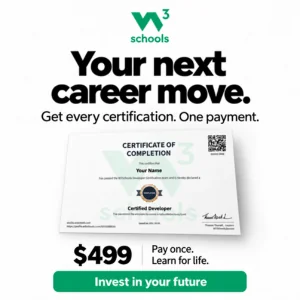

Overall score: 31.336123292467406 | status: partial | flagged: True


,Criterion,Score,Availability,Applied weight,Rule,Explanation / evidence,Reasons / needs review
0,exposure_brightness,0.000000,ok,0.3,pass_fail_thresholds,mean_luminance 223.844 >= mean_luminance_min 40 | mean_luminance 223.844 <= mean_luminance_max 215 | near_black_fraction 0.0402667 <= near_black_fraction_max 0.2 | near_white_fraction 0.706567 <= near_white_fraction_max 0.2,mean_luminance 223.844 <= mean_luminance_max 215 | near_white_fraction 0.706567 <= near_white_fraction_max 0.2
1,contrast,0.000000,ok,0.3,pass_fail_thresholds,luminance_std 64.795 >= luminance_std_min 20 | luminance_std 64.795 <= luminance_std_max 90 | p5_p95_range 216 >= p5_p95_range_min 50 | p5_p95_range 216 <= p5_p95_range_max 240 | near_black_fraction 0.0402667 <= near_black_fraction_max 0.2 | near_white_fraction 0.706567 <= near_white_fraction_max 0.2,near_white_fraction 0.706567 <= near_white_fraction_max 0.2
2,color_palette_fit,78.340308,ok,0.4,linear_distance_to_0_100,palette_distance 8.66388 mapped by linear_distance_to_0_100 with palette_distance_max 40 -> 78.3403,
3,framing_subject_position,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.
4,sharpness_subject_emphasis,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.


All CV measurements:


,Criterion,Measurement,Value
0,exposure_brightness,mean_luminance,223.8435111111111
1,exposure_brightness,near_black_fraction,0.040266666666666666
2,exposure_brightness,near_white_fraction,0.7065666666666667
3,contrast,luminance_std,64.79497117065053
4,contrast,p5_p95_range,216.0
5,contrast,near_black_fraction,0.040266666666666666
6,contrast,near_white_fraction,0.7065666666666667
7,color_palette_fit,dominant_colors,"[{'rgb': [249, 251, 250], 'hex': '#F9FBFA', 'lab': [98.38113161448942, -0.4807191016391559, 0.09403169337098427], 'proportion': 0.8188444444444445}, {'rgb': [190, 192, 191], 'hex': '#BEC0BF', 'lab': [77.5049575943132, -1.1050056306306402, 0.44473536036036176], 'proportion': 0.055433333333333334}, {'rgb': [12, 12, 13], 'hex': '#0C0C0D', 'lab': [3.3646931712864188, 0.010904888319284822, -0.17564536799707808], 'proportion': 0.05425555555555556}, {'rgb': [34, 161, 110], 'hex': '#22A16E', 'lab': [58.99985213873745, -45.72008496422583, 17.159952388468184], 'proportion': 0.046844444444444445}, {'rgb': [96, 97, 97], 'hex': '#606161', 'lab': [41.097761163418575, -0.2255654281098627, -0.23645749192245524], 'proportion': 0.024622222222222222}]"
8,color_palette_fit,palette_distance,8.663876707532594



=== Image 10: https://www.w3schools.com/images/img_fa_nextmove_300.png ===


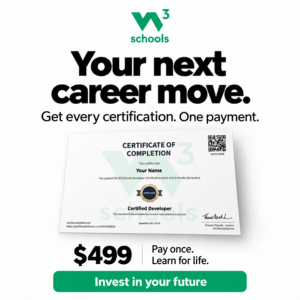

Overall score: 31.10151210186777 | status: partial | flagged: True


,Criterion,Score,Availability,Applied weight,Rule,Explanation / evidence,Reasons / needs review
0,exposure_brightness,0.00000,ok,0.3,pass_fail_thresholds,mean_luminance 223.414 >= mean_luminance_min 40 | mean_luminance 223.414 <= mean_luminance_max 215 | near_black_fraction 0.0398889 <= near_black_fraction_max 0.2 | near_white_fraction 0.697733 <= near_white_fraction_max 0.2,mean_luminance 223.414 <= mean_luminance_max 215 | near_white_fraction 0.697733 <= near_white_fraction_max 0.2
1,contrast,0.00000,ok,0.3,pass_fail_thresholds,luminance_std 64.7894 >= luminance_std_min 20 | luminance_std 64.7894 <= luminance_std_max 90 | p5_p95_range 216 >= p5_p95_range_min 50 | p5_p95_range 216 <= p5_p95_range_max 240 | near_black_fraction 0.0398889 <= near_black_fraction_max 0.2 | near_white_fraction 0.697733 <= near_white_fraction_max 0.2,near_white_fraction 0.697733 <= near_white_fraction_max 0.2
2,color_palette_fit,77.75378,ok,0.4,linear_distance_to_0_100,palette_distance 8.89849 mapped by linear_distance_to_0_100 with palette_distance_max 40 -> 77.7538,
3,framing_subject_position,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.
4,sharpness_subject_emphasis,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.


All CV measurements:


,Criterion,Measurement,Value
0,exposure_brightness,mean_luminance,223.41414444444445
1,exposure_brightness,near_black_fraction,0.03988888888888889
2,exposure_brightness,near_white_fraction,0.6977333333333333
3,contrast,luminance_std,64.78936200352322
4,contrast,p5_p95_range,216.0
5,contrast,near_black_fraction,0.03988888888888889
6,contrast,near_white_fraction,0.6977333333333333
7,color_palette_fit,dominant_colors,"[{'rgb': [249, 250, 250], 'hex': '#F9FAFA', 'lab': [98.11677630478364, -0.3716370628255703, -0.08661188477452908], 'proportion': 0.8185777777777777}, {'rgb': [189, 192, 190], 'hex': '#BDC0BE', 'lab': [77.53920908634792, -1.4886877828054244, 0.8317362077967279], 'proportion': 0.057055555555555554}, {'rgb': [12, 11, 12], 'hex': '#0C0B0C', 'lab': [3.1440555348124946, 0.260454963235246, -0.2410328584558894], 'proportion': 0.05391111111111111}, {'rgb': [22, 162, 107], 'hex': '#16A26B', 'lab': [59.11060727875784, -48.13695447198234, 19.387372036637775], 'proportion': 0.04583333333333333}, {'rgb': [95, 95, 97], 'hex': '#5F5F61', 'lab': [40.48891347083642, 0.007761604234533426, -0.9789673249185633], 'proportion': 0.024622222222222222}]"
8,color_palette_fit,palette_distance,8.898487898132231



=== Image 11: https://www.w3schools.com/adventure/img/map/oakTree.webp ===


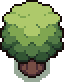

Overall score: 1.8418316736087004 | status: partial | flagged: True


,Criterion,Score,Availability,Applied weight,Rule,Explanation / evidence,Reasons / needs review
0,exposure_brightness,0.000000,ok,0.3,pass_fail_thresholds,mean_luminance 152.385 >= mean_luminance_min 40 | mean_luminance 152.385 <= mean_luminance_max 215 | near_black_fraction 0 <= near_black_fraction_max 0.2 | near_white_fraction 0.257622 <= near_white_fraction_max 0.2,near_white_fraction 0.257622 <= near_white_fraction_max 0.2
1,contrast,0.000000,ok,0.3,pass_fail_thresholds,luminance_std 78.3125 >= luminance_std_min 20 | luminance_std 78.3125 <= luminance_std_max 90 | p5_p95_range 239 >= p5_p95_range_min 50 | p5_p95_range 239 <= p5_p95_range_max 240 | near_black_fraction 0 <= near_black_fraction_max 0.2 | near_white_fraction 0.257622 <= near_white_fraction_max 0.2,near_white_fraction 0.257622 <= near_white_fraction_max 0.2
2,color_palette_fit,4.604579,ok,0.4,linear_distance_to_0_100,palette_distance 38.1582 mapped by linear_distance_to_0_100 with palette_distance_max 40 -> 4.60458,
3,framing_subject_position,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.
4,sharpness_subject_emphasis,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.


All CV measurements:


,Criterion,Measurement,Value
0,exposure_brightness,mean_luminance,152.38490853658536
1,exposure_brightness,near_black_fraction,0.0
2,exposure_brightness,near_white_fraction,0.2576219512195122
3,contrast,luminance_std,78.3125024146391
4,contrast,p5_p95_range,239.0
5,contrast,near_black_fraction,0.0
6,contrast,near_white_fraction,0.2576219512195122
7,color_palette_fit,dominant_colors,"[{'rgb': [158, 189, 98], 'hex': '#9EBD62', 'lab': [72.49702913215359, -25.057793674698804, 42.37432228915665], 'proportion': 0.3163109756097561}, {'rgb': [255, 255, 255], 'hex': '#FFFFFF', 'lab': [99.99999999999983, 7.283063041541027e-14, 1.6697754290362354e-13], 'proportion': 0.2576219512195122}, {'rgb': [69, 106, 61], 'hex': '#456A3D', 'lab': [40.998960344978805, -22.692123127340757, 20.828242041198465], 'proportion': 0.2035060975609756}, {'rgb': [45, 34, 30], 'hex': '#2D221E', 'lab': [14.46827479771192, 4.3995535714286245, 4.542131696428562], 'proportion': 0.17073170731707318}, {'rgb': [152, 169, 152], 'hex': '#98A998', 'lab': [67.46215820312499, -9.203125000000007, 6.734374999999959], 'proportion': 0.051829268292682924}]"
8,color_palette_fit,palette_distance,38.1581683263913



=== Image 12: https://www.w3schools.com/adventure/img/map/birchTree.webp ===


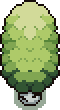

Not scored: ValueError: Image excluded by the preprocessor's geometry filter.

=== Image 13: https://www.w3schools.com/adventure/img/map/bush.webp ===


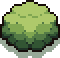

Not scored: ValueError: Image excluded by the preprocessor's geometry filter.

=== Image 14: https://www.w3schools.com/adventure/img/map/leaf.png ===


Not scored: ValueError: Image excluded by the preprocessor's geometry filter.

=== Image 15: https://www.w3schools.com/adventure/img/map/oakTreeLog.webp ===


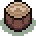

Not scored: ValueError: Image excluded by the preprocessor's geometry filter.

=== Image 16: https://www.w3schools.com/adventure/img/map/stone.webp ===


Not scored: ValueError: Image excluded by the preprocessor's geometry filter.

=== Image 17: https://www.w3schools.com/adventure/img/map/mushroom.png ===


Not scored: ValueError: Image excluded by the preprocessor's geometry filter.

=== Image 18: https://www.w3schools.com/adventure/img/map/adventure_sign.webp ===


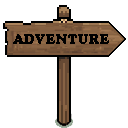

Overall score: 23.90779406928013 | status: partial | flagged: True


,Criterion,Score,Availability,Applied weight,Rule,Explanation / evidence,Reasons / needs review
0,exposure_brightness,0.000000,ok,0.3,pass_fail_thresholds,mean_luminance 196.628 >= mean_luminance_min 40 | mean_luminance 196.628 <= mean_luminance_max 215 | near_black_fraction 0.0884399 <= near_black_fraction_max 0.2 | near_white_fraction 0.678467 <= near_white_fraction_max 0.2,near_white_fraction 0.678467 <= near_white_fraction_max 0.2
1,contrast,0.000000,ok,0.3,pass_fail_thresholds,luminance_std 89.0576 >= luminance_std_min 20 | luminance_std 89.0576 <= luminance_std_max 90 | p5_p95_range 255 >= p5_p95_range_min 50 | p5_p95_range 255 <= p5_p95_range_max 240 | near_black_fraction 0.0884399 <= near_black_fraction_max 0.2 | near_white_fraction 0.678467 <= near_white_fraction_max 0.2,p5_p95_range 255 <= p5_p95_range_max 240 | near_white_fraction 0.678467 <= near_white_fraction_max 0.2
2,color_palette_fit,59.769485,ok,0.4,linear_distance_to_0_100,palette_distance 16.0922 mapped by linear_distance_to_0_100 with palette_distance_max 40 -> 59.7695,
3,framing_subject_position,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.
4,sharpness_subject_emphasis,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.


All CV measurements:


,Criterion,Measurement,Value
0,exposure_brightness,mean_luminance,196.62811279296875
1,exposure_brightness,near_black_fraction,0.08843994140625
2,exposure_brightness,near_white_fraction,0.678466796875
3,contrast,luminance_std,89.05760029396755
4,contrast,p5_p95_range,255.0
5,contrast,near_black_fraction,0.08843994140625
6,contrast,near_white_fraction,0.678466796875
7,color_palette_fit,dominant_colors,"[{'rgb': [255, 255, 255], 'hex': '#FFFFFF', 'lab': [99.98305383289814, -0.0015849618149146316, 0.0014544025157237073], 'proportion': 0.6793212890625}, {'rgb': [131, 95, 64], 'hex': '#835F40', 'lab': [43.35306255121085, 11.003186453022579, 23.370686908230155], 'proportion': 0.1676025390625}, {'rgb': [2, 2, 2], 'hex': '#020202', 'lab': [0.49231889740072177, 0.04307347520107241, 0.06672042560321678], 'proportion': 0.091064453125}, {'rgb': [105, 75, 52], 'hex': '#694B34', 'lab': [34.54854302551189, 9.80036327608983, 18.493745871862615], 'proportion': 0.04620361328125}, {'rgb': [171, 143, 107], 'hex': '#AB8F6B', 'lab': [61.199173503861005, 5.047236969111969, 23.40993001930502], 'proportion': 0.01580810546875}]"
8,color_palette_fit,palette_distance,16.09220593071987



=== Image 19: https://www.w3schools.com/adventure/img/map/chest.webp ===


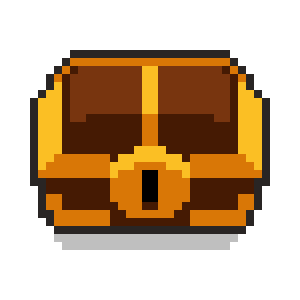

Overall score: 17.81015370834029 | status: partial | flagged: True


,Criterion,Score,Availability,Applied weight,Rule,Explanation / evidence,Reasons / needs review
0,exposure_brightness,0.000000,ok,0.3,pass_fail_thresholds,mean_luminance 177.182 >= mean_luminance_min 40 | mean_luminance 177.182 <= mean_luminance_max 215 | near_black_fraction 0.00568889 <= near_black_fraction_max 0.2 | near_white_fraction 0.515733 <= near_white_fraction_max 0.2,near_white_fraction 0.515733 <= near_white_fraction_max 0.2
1,contrast,0.000000,ok,0.3,pass_fail_thresholds,luminance_std 90.8046 >= luminance_std_min 20 | luminance_std 90.8046 <= luminance_std_max 90 | p5_p95_range 219 >= p5_p95_range_min 50 | p5_p95_range 219 <= p5_p95_range_max 240 | near_black_fraction 0.00568889 <= near_black_fraction_max 0.2 | near_white_fraction 0.515733 <= near_white_fraction_max 0.2,luminance_std 90.8046 <= luminance_std_max 90 | near_white_fraction 0.515733 <= near_white_fraction_max 0.2
2,color_palette_fit,44.525384,ok,0.4,linear_distance_to_0_100,palette_distance 22.1898 mapped by linear_distance_to_0_100 with palette_distance_max 40 -> 44.5254,
3,framing_subject_position,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.
4,sharpness_subject_emphasis,NaN,unavailable_needs_review,0.0,pass_fail_thresholds,,No subject detector was supplied. | No subject detector was supplied.


All CV measurements:


,Criterion,Measurement,Value
0,exposure_brightness,mean_luminance,177.1824
1,exposure_brightness,near_black_fraction,0.005688888888888889
2,exposure_brightness,near_white_fraction,0.5157333333333334
3,contrast,luminance_std,90.80462137784251
4,contrast,p5_p95_range,219.0
5,contrast,near_black_fraction,0.005688888888888889
6,contrast,near_white_fraction,0.5157333333333334
7,color_palette_fit,dominant_colors,"[{'rgb': [251, 251, 251], 'hex': '#FBFBFB', 'lab': [98.65940213922084, 1.021405182655144e-12, 2.0961010704922955e-12], 'proportion': 0.5470222222222222}, {'rgb': [87, 36, 9], 'hex': '#572409', 'lab': [21.203735539655682, 21.980914146763798, 27.13216848035478], 'proportion': 0.20764444444444444}, {'rgb': [217, 119, 6], 'hex': '#D97706', 'lab': [59.7106933593748, 32.35937499999951, 65.82812499999957], 'proportion': 0.1152}, {'rgb': [38, 34, 34], 'hex': '#262222', 'lab': [13.80847536361405, 1.564399904775927, 1.24864946527968], 'proportion': 0.06897777777777778}, {'rgb': [251, 191, 36], 'hex': '#FBBF24', 'lab': [80.57861328124991, 9.062499999999998, 77.09374999999993], 'proportion': 0.06115555555555555}]"
8,color_palette_fit,palette_distance,22.189846291659713



Page errors: []
Download errors: [DownloadFailure(url='https://www.w3schools.com/adventure/img/lynx-7.webp', code=<DownloadCode.UNSUPPORTED_TYPE: 'unsupported_type'>, message='Animated or multi-frame images are not supported.')]


In [3]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)

for idx, photo in enumerate(result.images, 1):
    print(f'\n=== Image {idx}: {photo["url"]} ===')
    if photo['preview'] is not None:
        display(photo['preview'])
    if photo['path'] is not None:
        print('Saved at:', photo['path'])
    if photo['error'] is not None:
        print('Not scored:', photo['error'])
        continue

    score = photo['score']
    print(f'Overall score: {score.overall_score} | status: {score.status} | flagged: {score.flagged}')

    # Every criterion's scoring outcome, evidence, and unavailable reasons.
    summary = []
    for c in score.criteria:
        cv = photo['cv_results'].get(c.criterion_id, {})
        summary.append({
            'Criterion': c.criterion_id,
            'Score': c.score,
            'Availability': c.availability,
            'Applied weight': c.weight,
            'Rule': c.rule_id,
            'Explanation / evidence': ' | '.join(str(v) for v in c.evidence),
            'Reasons / needs review': ' | '.join(str(v) for v in (
                list(c.reasons) + list(cv.get('reasons') or [])
            )),
        })
    display(pd.DataFrame(summary))

    # All returned measurements, one measurement per row.
    measurements = []
    for criterion_id, output in photo['cv_results'].items():
        for name, value in (output.get('measurements') or {}).items():
            measurements.append({
                'Criterion': criterion_id,
                'Measurement': name,
                'Value': str(value),
            })
    if measurements:
        print('All CV measurements:')
        display(pd.DataFrame(measurements))
    else:
        print('No CV measurements returned for this image.')

    if photo['vlm_results']:
        print('Raw VLM results:')
        for criterion_id, output in photo['vlm_results'].items():
            print(criterion_id, output)

print('\nPage errors:', result.discovery.failed_pages)
print('Download errors:', result.download_failures)


## Notes

- Image URLs are still fetched over HTTP when `SAVE_IMAGES=False`; the temporary files are deleted before the pipeline returns. Only the small PIL previews and scoring records remain in memory.
- Framing and sharpness can report `unavailable_needs_review` when no subject detector is configured; this is expected rather than a silently generated score.
- This notebook uses the **actual** preprocessing and scoring in `pipeline.score_photo()`. It does not create new scoring rules or explanations.
